### Import Dataset

In [1]:
import pandas as pd
import os
import kagglehub # May need to install this package if not already installed (pip install kagglehub)

path = kagglehub.dataset_download("dillonmyrick/bells-palsy-clinical-trial")
files = os.listdir(path) # Lists files

csv_file = [f for f in files if f.endswith('.csv')][0] # Find the first file that ends in .csv
csv_path = os.path.join(path, csv_file) # Join path and CSV file

df = pd.read_csv(csv_path)

### Data Cleaning

In [2]:
import pandas as pd

raw = df.copy() # Keep a copy of the raw data for reference

#Changing Sex to dummy variables, Male = 1, Female = 0
df["Sex"]= (df["Sex"] == "Male").astype(int)

#Changing Within 24 hr to 0, >24 to ≤48 hr to 1, >48 to ≤72 hr to 2, REMOVED the Unknown
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].map({"Within 24 hr": 0, ">24 to ≤48 hr": 1, ">48 to ≤72 hr": 2})

#Changing Received Prednisolone to No = 0, Yes = 1 and Received Acyclovir to No = 0, Yes = 1
df["Received Prednisolone"] = df["Received Prednisolone"].map({"Yes": 1, "No": 0})
df["Received Acyclovir"] = df["Received Acyclovir"].map({"Yes": 1, "No": 0})

#Changing Full Recovery in 3 months to No = 0, Yes = 1 and Full Recovery in 9 months to No = 0, Yes = 1
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].map({"No": 0, "Yes": 1})
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].map({"No": 0, "Yes": 1})

#Dropping Treatment Group since its the same as received prednislone/acyclovir
df= df.drop("Treatment Group", axis = 1)

#Convert to floats
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].astype("Int64") # supports missing values
df["Received Prednisolone"] = df["Received Prednisolone"].astype(int)
df["Received Acyclovir"] = df["Received Acyclovir"].astype(int)
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].astype(int)
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].astype(int)

#Drop NA Rows
df = df.dropna()

## Statistics

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Age and Sex Distribution

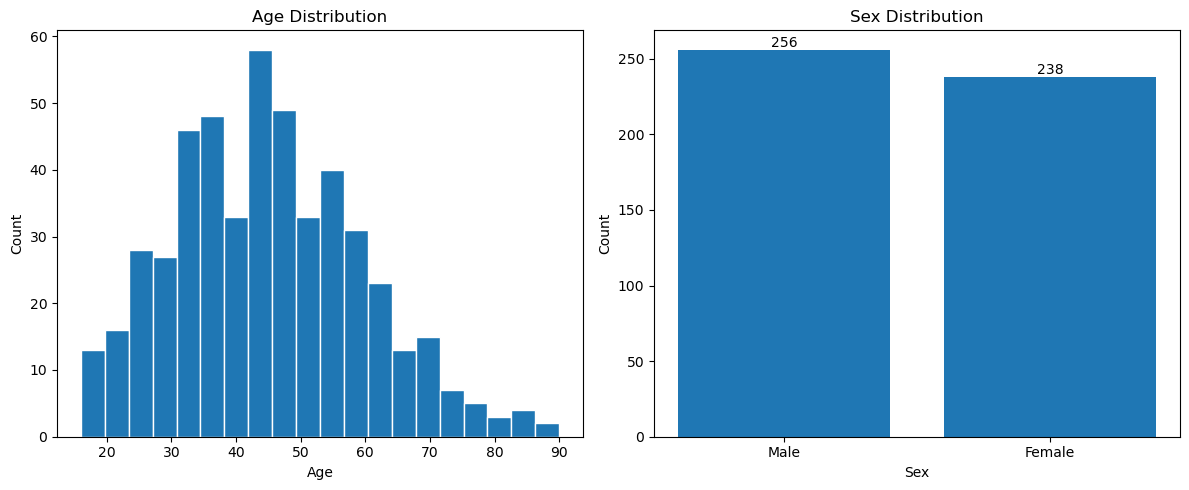

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(raw["Age"], bins=20, edgecolor="white")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")
axes[0].grid(False)

sex_counts = raw["Sex"].value_counts()
bar1 = axes[1].bar(sex_counts.index, sex_counts.values)
axes[1].set_title("Sex Distribution")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Count")
axes[1].bar_label(bar1, fmt="{:,.0f}")

plt.tight_layout()
plt.show()


### Treatment Groups and Recovery

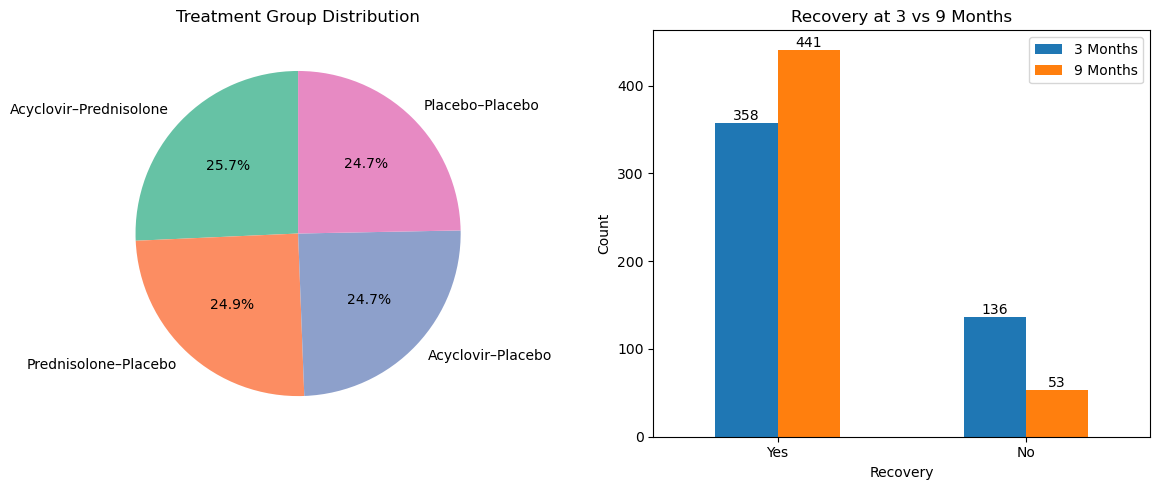

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

trt_counts = raw["Treatment Group"].value_counts()
axes[0].pie(trt_counts.values, labels=trt_counts.index,
            autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2", len(trt_counts)))
axes[0].set_title("Treatment Group Distribution")

# recovery at 3 vs 9 months
recovery = pd.DataFrame({
    "3 Months": raw["Full Recovery in 3 Months"].value_counts(),
    "9 Months": raw["Full Recovery in 9 Months"].value_counts()
})
ax_rec = recovery.plot(kind="bar", ax=axes[1]) # Plot the recovery counts as a grouped bar chart
axes[1].set_title("Recovery at 3 vs 9 Months")
axes[1].set_xlabel("Recovery")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=0)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:,.0f}")


plt.tight_layout()
plt.show()

### Baseline, 3, 9 Month HB Scores + Time between onset and treatment

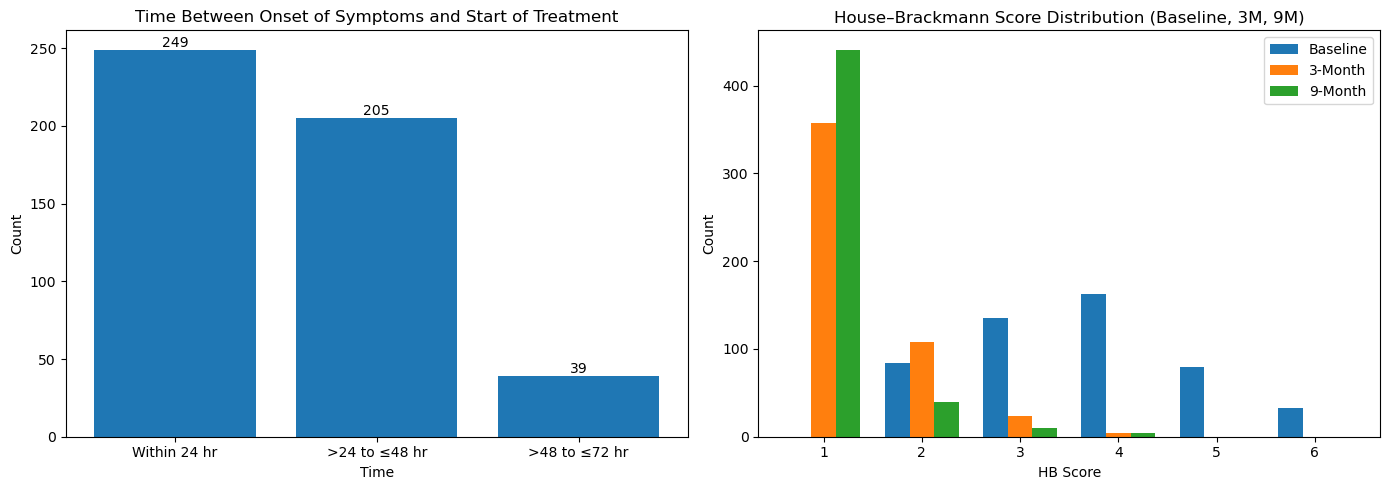

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

time_counts = (raw["Time between onset of symptoms and start of treatment"].value_counts().drop("Unknown"))
bar2 = axes[0].bar(time_counts.index, time_counts.values)
axes[0].set_title("Time Between Onset of Symptoms and Start of Treatment")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Count")
axes[0].bar_label(bar2, fmt="{:,.0f}") 

# overlay all three HB score distributions on one plot
baseline_counts = raw["Baseline Score on House–Brackmann scale"].value_counts().sort_index()
month3_counts = raw["3-Month Score on House–Brackmann scale"].value_counts().sort_index()
month9_counts = raw["9-Month Score on House–Brackmann scale"].value_counts().sort_index()

all_scores = sorted(set(baseline_counts.index) | set(month3_counts.index) | set(month9_counts.index)) # Get all unique scores across the three time points
x = np.arange(len(all_scores))
width = 0.25

axes[1].bar(x - width, [baseline_counts.get(s, 0) for s in all_scores], width=width, label="Baseline") # Sets baseline bars to be left of center
axes[1].bar(x, [month3_counts.get(s, 0) for s in all_scores],width=width, label="3-Month") # Sets 3-month bars to be centered
axes[1].bar(x + width, [month9_counts.get(s, 0) for s in all_scores], width=width, label="9-Month") # Sets 9-month bars to be right of center
axes[1].set_xticks(x)
axes[1].set_xticklabels(all_scores)
axes[1].set_title("House–Brackmann Score Distribution (Baseline, 3M, 9M)")
axes[1].set_xlabel("HB Score")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

### Recovery Rates by Treatment Group

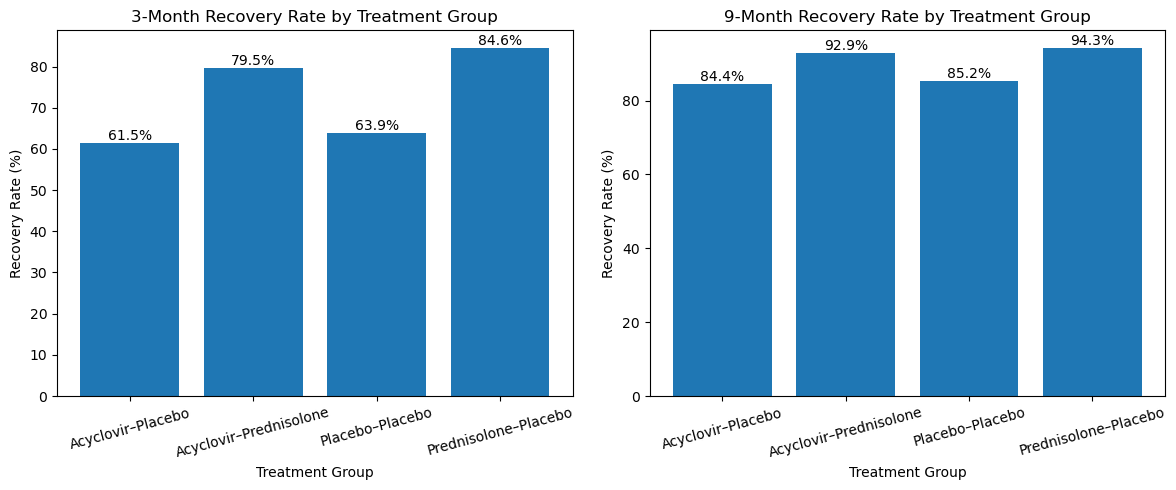

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

rate_3 = raw.groupby("Treatment Group")["Full Recovery in 3 Months"].apply(
    lambda x: (x == "Yes").mean() * 100) # Calculate recovery rate as percentage
bar5 = axes[0].bar(rate_3.index, rate_3.values)
axes[0].set_title("3-Month Recovery Rate by Treatment Group")
axes[0].set_xlabel("Treatment Group")
axes[0].set_ylabel("Recovery Rate (%)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].bar_label(bar5, fmt="{:.1f}%")

rate_9 = raw.groupby("Treatment Group")["Full Recovery in 9 Months"].apply(
    lambda x: (x == "Yes").mean() * 100) # Calculate recovery rate as percentage
bar6 = axes[1].bar(rate_9.index, rate_9.values)
axes[1].set_title("9-Month Recovery Rate by Treatment Group")
axes[1].set_xlabel("Treatment Group")
axes[1].set_ylabel("Recovery Rate (%)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].bar_label(bar6, fmt="{:.1f}%")

plt.tight_layout()
plt.show()

### Correlation Matrix

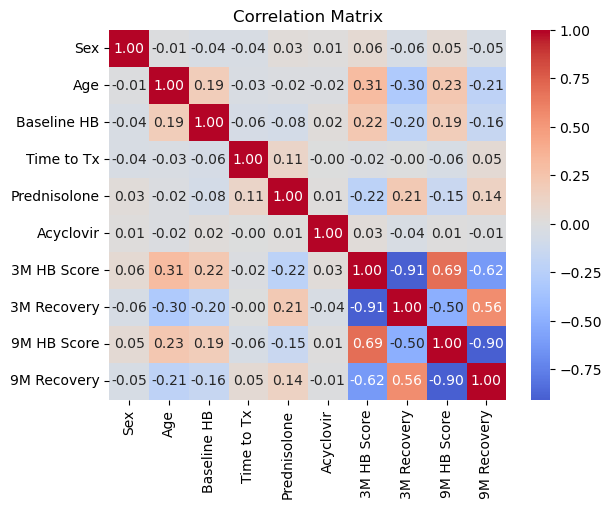

In [36]:
corr_cols = {
    "Sex": "Sex",
    "Age": "Age",
    "Baseline Score on House–Brackmann scale": "Baseline HB",
    "Time between onset of symptoms and start of treatment": "Time to Tx",
    "Received Prednisolone": "Prednisolone",
    "Received Acyclovir": "Acyclovir",
    "3-Month Score on House–Brackmann scale": "3M HB Score",
    "Full Recovery in 3 Months": "3M Recovery",
    "9-Month Score on House–Brackmann scale": "9M HB Score",
    "Full Recovery in 9 Months": "9M Recovery",
}
corr_df = df[list(corr_cols.keys())].rename(columns=corr_cols)
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()